# Lecture 9 · Learning a distribution with PyTorch

Two sensors measure the same signal. Both are accurate on average, but one gives much noisier readings. Can we train a model that predicts the next reading **and** tells us how far off it might be?

Open this notebook in Jupyter or Colab and run the cells in order. Everything runs on CPU. If the imports below fail in a new environment, run `%pip install torch matplotlib` in a cell and restart the kernel.

In [1]:
import math
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Normal
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(9)
sensor_names = ("Quiet sensor", "Noisy sensor")
sensor_colors = ("#126e82", "#b85b24")
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 1. Get PyTorch to reproduce a derivative we know

In Homework 2 a teacher gave class 1 probabilities of $0.8$ and $0.6$ for inputs $x=1$ and $x=2$. The student model predicts $q_a(x)=1/(1+e^{-ax})$. At $a=\log 4$, the first prediction matches the teacher. The second is too high. **Which way should $a$ move?**

A tensor holds numbers. Here `inputs` holds two numbers and `a` holds one. Setting `requires_grad=True` on `a` tells PyTorch to record operations that depend on it. The logits are the raw scores $ax$. Below, `detach()` gives us their values for printing without extending the gradient calculation. The loss function accepts those scores directly and averages the binary cross-entropy over the two inputs.

In [2]:
inputs = torch.tensor([1., 2.])
targets = torch.tensor([0.8, 0.6])
a = torch.tensor(math.log(4), requires_grad=True)

logits = a * inputs
loss = F.binary_cross_entropy_with_logits(logits, targets)
print("Predicted probabilities:", [round(q, 4) for q in logits.detach().sigmoid().tolist()])
print(f"Mean loss: {loss.item():.4f}")
print("Gradient before backward:", a.grad)

Predicted probabilities: [0.8, 0.9412]
Mean loss: 0.8350
Gradient before backward: None


`loss.backward()` starts at the scalar loss and follows the recorded operations back to `a`, applying the chain rule. Both predictions used the same `a`. Lecture 8 gives us a check: each input contributes $x(q_a(x)-p_x)$, where $p_x$ is its target. Since the loss is a mean, its derivative is the mean of the two contributions.

In [3]:
loss.backward()
with torch.no_grad():
    contributions = inputs * (logits.sigmoid() - targets)
print("Per-input derivatives:", [round(v, 4) for v in contributions.tolist()])
print(f"Autograd: {a.grad.item():.4f}    By hand: {contributions.mean().item():.4f}")
print(f"a after backward: {a.item():.4f}")
torch.testing.assert_close(a.grad, contributions.mean())

Per-input derivatives: [0.0, 0.6824]
Autograd: 0.3412    By hand: 0.3412
a after backward: 1.3863


The second input gives a positive derivative, so a small decrease in `a` lowers the loss. `backward()` stored the slope in `a.grad`. Changing the parameter is a separate step. Below, an optimizer will take that step.

## 2. Look at what each sensor measures

Let $x$ be a reference signal and $Y$ a sensor reading. At any fixed $x$, both sensors have mean $1+2x$. Their **standard deviations** differ: $0.4$ for the quiet sensor and $1.2$ for the noisy one. We can simulate a reading by adding $\sigma_s Z$ to the mean, where $Z\sim\mathcal N(0,1)$ and $s$ is the sensor ID.

We'll fit the models to 640 readings, then check their predictions on 4,000 fresh readings. Each set contains equal numbers from each sensor. The training code sees the readings and IDs. The true mean and noise levels are available to us for comparison.

In [4]:
true_sd = torch.tensor([0.4, 1.2])

def sample_readings(per_sensor, seed):
    rng = torch.Generator().manual_seed(seed)
    sensor = torch.arange(2).repeat_interleave(per_sensor)
    x = 4 * torch.rand(len(sensor), 1, generator=rng) - 2
    noise = torch.randn(len(sensor), generator=rng)
    y = 1 + 2 * x[:, 0] + true_sd[sensor] * noise
    return x, sensor, y

x_train, s_train, y_train = sample_readings(320, seed=93)
x_test, s_test, y_test = sample_readings(2000, seed=94)
print("Training shapes (x, sensor, y):", x_train.shape, s_train.shape, y_train.shape)

Training shapes (x, sensor, y): torch.Size([640, 1]) torch.Size([640]) torch.Size([640])


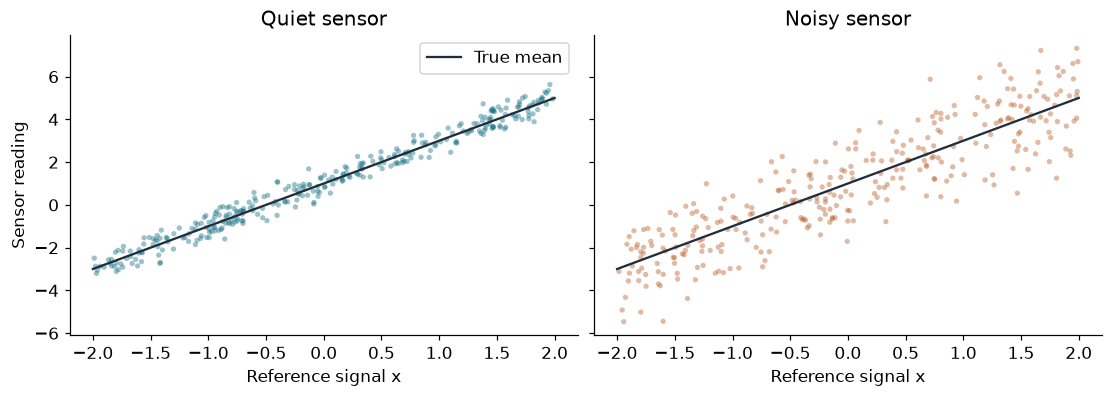

In [5]:
grid = torch.linspace(-2, 2, 150)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True,
                         layout="constrained")
for s, ax in enumerate(axes):
    mask = s_train == s
    ax.scatter(x_train[mask, 0], y_train[mask], s=12, alpha=0.42,
               color=sensor_colors[s], edgecolors="none")
    ax.plot(grid, 1 + 2 * grid, color="#202d3b", label="True mean")
    ax.set(title=sensor_names[s], xlabel="Reference signal x")
axes[0].set_ylabel("Sensor reading")
axes[0].legend()
plt.show()

## 3. Fit the mean, one batch at a time

`nn.Linear(1, 1)` has two trainable numbers, a weight $w$ and a bias $b$. It predicts $\mu(x)=wx+b$. We'll start both at zero so we can watch the line move. `torch.no_grad()` lets us set their starting values without recording the assignment as part of the calculation.

First fit a Gaussian with a fixed standard deviation of 1. Its negative log likelihood per reading is $\tfrac12(y-\mu)^2$ plus a constant, so minimizing it fits the usual least-squares line. `Normal(mu, 1.0).log_prob(y)` evaluates the log density at each observed reading.

In [6]:
mean_model = nn.Linear(1, 1)
with torch.no_grad():
    mean_model.weight.zero_()
    mean_model.bias.zero_()

learning_rate = 0.08
optimizer = torch.optim.SGD(mean_model.parameters(), lr=learning_rate)
batches = DataLoader(TensorDataset(x_train, y_train), batch_size=64, shuffle=True,
                     generator=torch.Generator().manual_seed(95))

Take one batch and inspect the weight before and after its update. A batch of 64 inputs has shape `(64, 1)`. `squeeze(-1)` takes the model output from `(64, 1)` to `(64,)` so each prediction is paired with its own reading. Each call to `zero_grad()` clears derivatives left over from the previous batch.

In [7]:
def take_step(x_batch, y_batch):
    optimizer.zero_grad()
    mu = mean_model(x_batch).squeeze(-1)
    assert mu.shape == y_batch.shape
    batch_loss = -Normal(mu, 1.0).log_prob(y_batch).mean()
    batch_loss.backward()
    optimizer.step()

x_batch, y_batch = next(iter(batches))
w_before = mean_model.weight.item()
take_step(x_batch, y_batch)
gradient = mean_model.weight.grad.item()
w_after = mean_model.weight.item()
print(f"Old weight {w_before:.3f}, gradient {gradient:.3f}, new weight {w_after:.3f}")
print(f"w − learning rate × gradient = {w_before - learning_rate * gradient:.3f}")
assert math.isclose(w_after, w_before - learning_rate * gradient, abs_tol=1e-6)

Old weight 0.000, gradient -2.973, new weight 0.238
w − learning rate × gradient = 0.238


An **epoch** is one pass through all the training readings. Continue from that first update for 20 epochs. The lines below show what the same model predicts at three points during training.

Fitted mean: 0.967 + 2.042 x


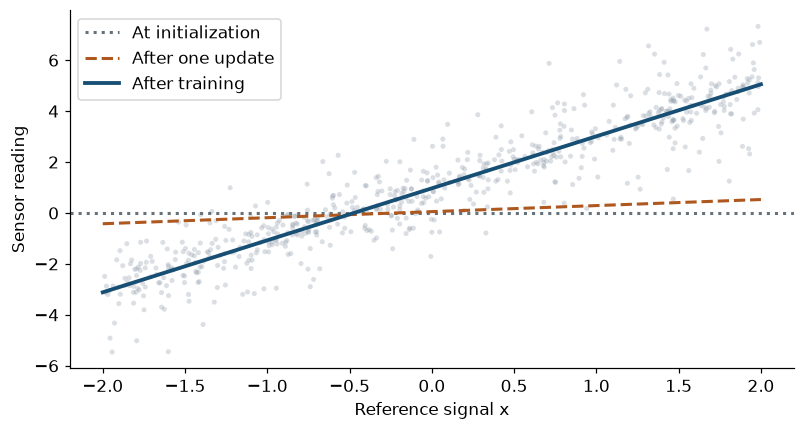

In [8]:
first_line = (w_after, mean_model.bias.item())
for epoch in range(20):
    for x_batch, y_batch in batches:
        take_step(x_batch, y_batch)

slope, intercept = mean_model.weight.item(), mean_model.bias.item()
print(f"Fitted mean: {intercept:.3f} + {slope:.3f} x")
fig, ax = plt.subplots(figsize=(7.2, 3.8), layout="constrained")
ax.scatter(x_train[:, 0], y_train, color="#8997a5", s=11, alpha=0.30, edgecolors="none")
ax.axhline(0, color="#65717b", linestyle=":", linewidth=2, label="At initialization")
ax.plot(grid, first_line[0] * grid + first_line[1], "--", color="#ae571e",
        linewidth=2, label="After one update")
ax.plot(grid, slope * grid + intercept, color="#174e73", linewidth=2.5,
        label="After training")
ax.set(xlabel="Reference signal x", ylabel="Sensor reading")
ax.legend()
plt.show()

## 4. How wide should the prediction be?

Keep the fitted line fixed. All that changes in this experiment is the width of the Gaussian around it. We'll fit one model with a **shared** standard deviation and another with **one per sensor**.

Write $r=y-\hat\mu(x)$ for a residual. Up to a constant, one reading contributes the following negative log likelihood:

$$\ell(\sigma;r)=\log\sigma+\frac{r^2}{2\sigma^2}.$$

If a reading falls far from the line, increasing $\sigma$ reduces the second term. The first term grows, so the model pays for making every prediction wider. For this fit we can subtract the line once and use a zero-mean Gaussian for the residuals. Across a group of readings the minimum occurs at $\hat\sigma=\sqrt{\operatorname{mean}(r^2)}$. We can check whether gradient descent finds it.

In [9]:
with torch.no_grad():
    residual = y_train - mean_model(x_train).squeeze(-1)

def fit_scales(group_ids, n_groups):
    log_sd = nn.Parameter(torch.zeros(n_groups))
    scale_optimizer = torch.optim.SGD([log_sd], lr=0.15)
    for _ in range(120):
        scale_optimizer.zero_grad()
        sd = log_sd[group_ids].exp()
        loss = -Normal(0.0, sd).log_prob(residual).mean()
        loss.backward()
        scale_optimizer.step()
    return log_sd.detach().exp()

shared_sd = fit_scales(torch.zeros_like(s_train), n_groups=1)
sensor_sd = fit_scales(s_train, n_groups=2)
print(f"Shared SD: {shared_sd.item():.3f}")
for s, name in enumerate(sensor_names):
    residual_rms = residual[s_train == s].square().mean().sqrt()
    print(f"{name}: fitted {sensor_sd[s]:.3f}, residual RMS {residual_rms:.3f}, "
          f"simulation SD {true_sd[s]:.1f}")
    torch.testing.assert_close(sensor_sd[s], residual_rms, atol=1e-4, rtol=1e-4)

Shared SD: 0.930
Quiet sensor: fitted 0.363, residual RMS 0.363, simulation SD 0.4
Noisy sensor: fitted 1.264, residual RMS 1.264, simulation SD 1.2


`nn.Parameter` marks a tensor as trainable. The optimizer updates `log_sd`, and `exp()` converts any real value into a positive standard deviation. Passing all zeros as group IDs makes every reading use the same parameter. Passing the sensor IDs routes quiet readings to parameter 0 and noisy readings to parameter 1.

With equal numbers of readings from each sensor and the true mean, the shared model would learn an SD near $\sqrt{(0.4^2+1.2^2)/2}\approx0.89$. **Which sensor will get a prediction band that's too narrow?**

## 5. Test the prediction intervals on new readings

For a Gaussian, the central 90% lies between the 5th and 95th percentiles. If $z$ is the 95th percentile of a standard normal, our interval for **one future reading** is $\hat\mu(x)\pm z\hat\sigma$. This is a prediction interval. A confidence interval for the mean answers a different question: how precisely have we estimated the average reading at $x$?

These bands use fitted parameters and treat them as known. Their advertised 90% coverage is something we can check. First look at the same test readings under each model. The lines show the fitted mean and the shaded regions show the intervals.

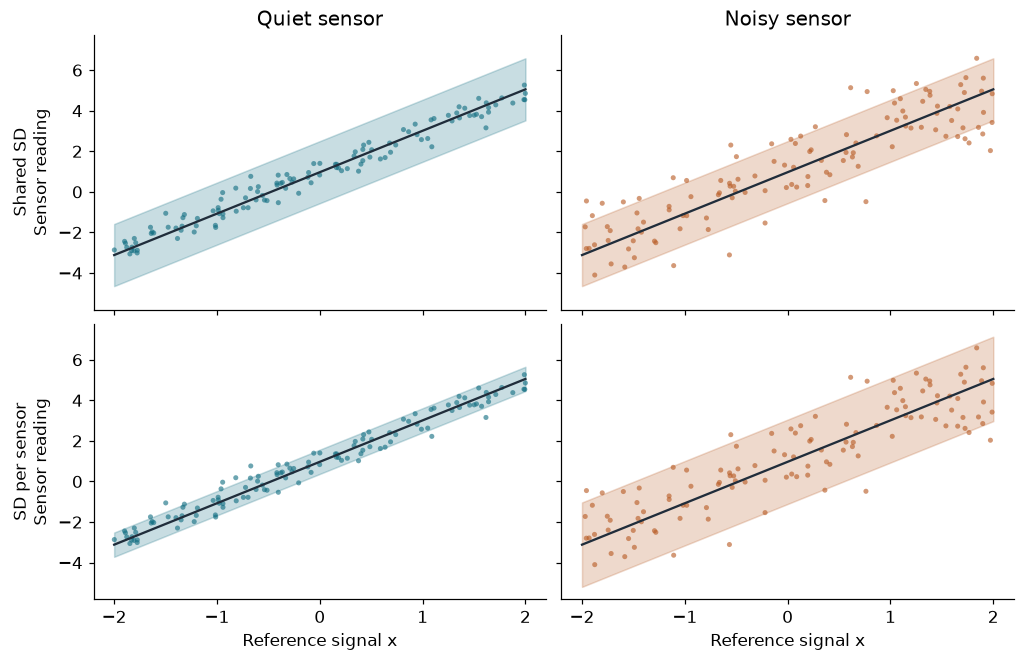

In [10]:
z = Normal(0., 1.).icdf(torch.tensor(0.95)).item()
with torch.no_grad():
    mu_test = mean_model(x_test).squeeze(-1)
    mu_grid = mean_model(grid[:, None]).squeeze(-1)

by_model = {"Shared SD": shared_sd.expand(2), "SD per sensor": sensor_sd}
fig, axes = plt.subplots(2, 2, figsize=(9.2, 5.9), sharex=True, sharey=True,
                         layout="constrained")
for row, (model_name, scales) in enumerate(by_model.items()):
    for s, ax in enumerate(axes[row]):
        half_width = z * scales[s]
        ax.fill_between(grid, mu_grid - half_width, mu_grid + half_width,
                        color=sensor_colors[s], alpha=0.23)
        idx = torch.where(s_test == s)[0][:120]
        ax.scatter(x_test[idx, 0], y_test[idx], s=11, alpha=0.62,
                   color=sensor_colors[s], edgecolors="none")
        ax.plot(grid, mu_grid, color="#202d3b", linewidth=1.5)
        if row == 0:
            ax.set_title(sensor_names[s])
        if s == 0:
            ax.set_ylabel(model_name + "\nSensor reading")
        if row == 1:
            ax.set_xlabel("Reference signal x")
plt.show()

**Coverage** is the fraction of test readings inside their interval. The scatterplots show only a subset. Use all 4,000 readings here. Check the overall number first, then look at each sensor on its own.

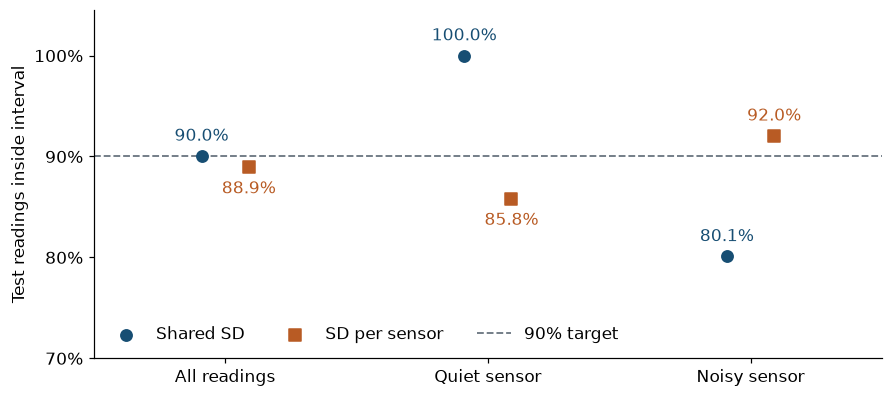

Shared SD | All readings: 90.0% | Quiet sensor: 100.0% | Noisy sensor: 80.1%
SD per sensor | All readings: 88.9% | Quiet sensor: 85.8% | Noisy sensor: 92.0%


In [11]:
groups = ("All readings", *sensor_names)
masks = (torch.ones_like(s_test, dtype=torch.bool), s_test == 0, s_test == 1)
coverage = {}
for model_name, scales in by_model.items():
    half_width = z * scales[s_test]
    inside = (y_test - mu_test).abs() <= half_width
    coverage[model_name] = [inside[mask].float().mean().item() for mask in masks]

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
for (name, rates), offset, marker, color in zip(
    coverage.items(), [-0.09, 0.09], ["o", "s"], ["#174e73", "#b85b24"]
):
    positions = [i + offset for i in range(3)]
    ax.scatter(positions, rates, marker=marker, color=color, s=55, label=name, zorder=3)
    for x, rate in zip(positions, rates):
        label_above = offset < 0 or rate > 0.905
        ax.annotate(f"{rate:.1%}", (x, rate), xytext=(0, 10 if label_above else -17),
                    textcoords="offset points", ha="center", color=color)
ax.axhline(0.9, linestyle="--", color="#6b7681", linewidth=1.2, label="90% target")
ax.set(xticks=range(3), xticklabels=groups, xlim=(-0.5, 2.5), ylim=(0.70, 1.045),
       ylabel="Test readings inside interval")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_yticks([0.7, 0.8, 0.9, 1.0])
ax.legend(loc="lower left", ncol=3, frameon=False)
plt.show()
for name, rates in coverage.items():
    print(name + " | " + " | ".join(f"{group}: {rate:.1%}" for group, rate in zip(groups, rates)))

Both models use the same line and make identical point predictions. In this run, the shared band covers 90.0% overall, including 100.0% of quiet readings and 80.1% of noisy ones. The overall number hides two errors in opposite directions.

Separate widths give 85.8% and 92.0%. Why only 85.8% for the quiet sensor? Its fitted SD was 0.363 from 320 training readings. The true SD was 0.4, so the fitted interval is a little too narrow. Estimating the mean and checking coverage on a finite test set also affect these numbers.

**Try it.** Imagine 80% of tomorrow’s readings come from the noisy sensor. Predict what will happen to overall coverage, then change `noisy_fraction` below. The two sensor-specific coverage rates stay fixed in this calculation.

In [12]:
noisy_fraction = 0.5
for name, (_, quiet_rate, noisy_rate) in coverage.items():
    expected = (1 - noisy_fraction) * quiet_rate + noisy_fraction * noisy_rate
    print(f"{name}: expected coverage {expected:.1%} with {noisy_fraction:.0%} noisy readings")

Shared SD: expected coverage 90.0% with 50% noisy readings
SD per sensor: expected coverage 88.9% with 50% noisy readings
